# L33 - Yule-Walker-/Autokorrelationsmethode (Lösung zu Aufgabe 33)

Für die Lösung MATLAB `*.m` Dateiformat bitte [hier klicken (`l33.m`)](./l33.m).

Weitere benötigne MATLAB `*.m`-Dateien:  [`lyw.m`](./lyw.m)

In [1]:
MA = 1;
AR = [1.0000 0.3611 -0.1373 0.2685 -0.0533 -0.3353 -0.307];
NFFT = 2^10;
n_a = length(AR);
n = n_a-1;          %Filterordnung

## Teilaufgabe a:  Einschwingverhalten

I.A./ exakte AKF (eingeschw. Zustand)

Anzahl notwendiger Abtastwerte fuer den Einschwingvorgang: N_vor=80



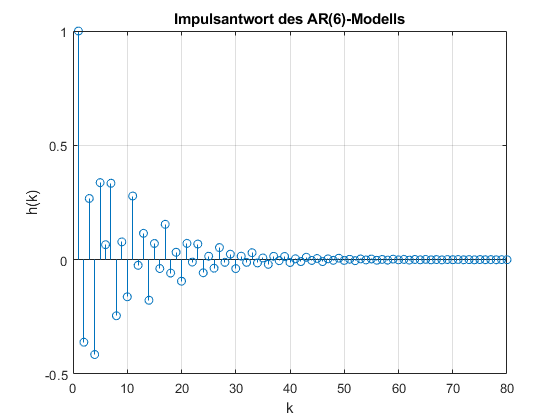

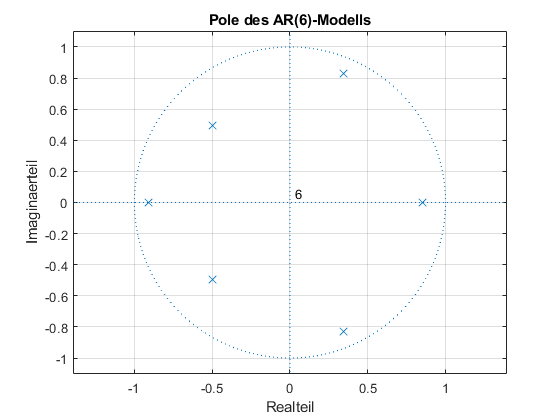

In [3]:
[h_arma,t] = impz(MA,AR,80);

% # grafische Ausgabe # %
figure;
stem(1:length(h_arma),h_arma(1:length(h_arma)));
grid;
xlabel('k');
ylabel('h(k)');
title(sprintf('Impulsantwort des AR(%d)-Modells',n));

figure;
[h1,h2,h3]=zplane(MA,AR);
set(h1,'Visible','off');
title(sprintf('Pole des AR(%d)-Modells',n));
grid;
xlabel('Realteil');
ylabel('Imaginaerteil');
disp('Anzahl notwendiger Abtastwerte fuer den Einschwingvorgang: N_vor=80');

##  Teilaufgabe b:  Exakte AKF r_xx(0)...r_xx(n), YW-Koeffizienten, LDS

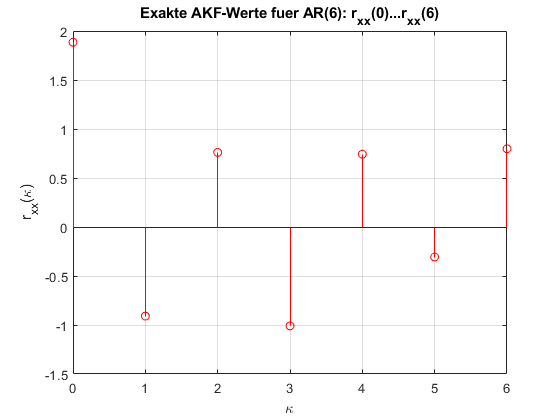

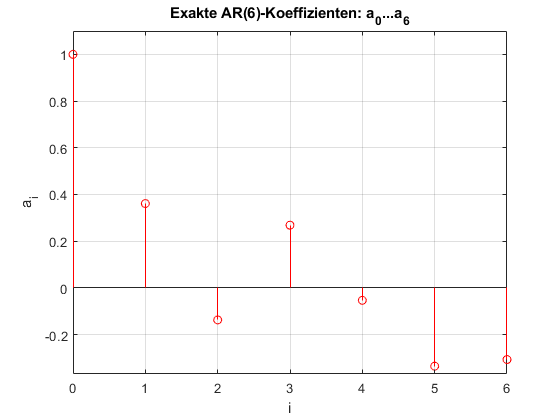

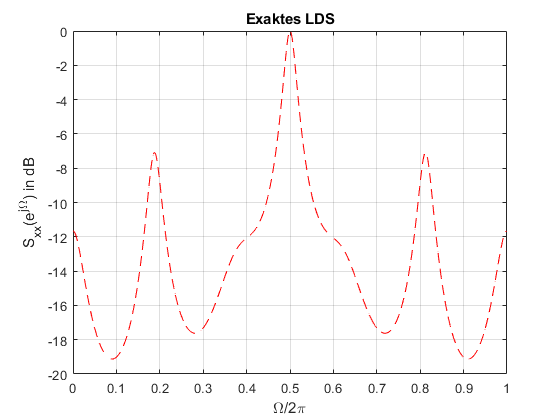

In [4]:
rxx        = xcorr(h_arma);
index      = (length(rxx)+1)/2;
rxx_ex     = rxx(index:index+n);
ARcoeff    = lyw(h_arma,n,0);
Omega_norm = 0:1/NFFT:1-1/NFFT;
Sxx_ex     = abs(fft(MA,NFFT)./fft(AR,NFFT)).^2;

% # grafische Ausgabe # %
figure;
stem(0:n,rxx_ex,'r-');
grid;
xlabel('\kappa');
ylabel('r_{xx}(\kappa)');
title(sprintf('Exakte AKF-Werte fuer AR(%d): r_{xx}(0)...r_{xx}(%d)',n,n));

figure;
stem(0:n,ARcoeff,'r');
axis([0 n 1.1*min(ARcoeff) 1.1*max(ARcoeff)]);
xlabel('i');
ylabel('a_i');
grid;
title(sprintf('Exakte AR(%d)-Koeffizienten: a_0...a_{%d}',n,n));

figure;
plot(Omega_norm, 10*log10(Sxx_ex/max(Sxx_ex)),'r--');
grid;
xlabel('\Omega/2\pi');
ylabel('S_{xx}(e^{j\Omega}) in dB');
title('Exaktes LDS');

##  Teilaufgabe c:  Einfluss der Laenge N der Datenfolge x(k)

....Bitte warten: Berechnung erfolgt.....



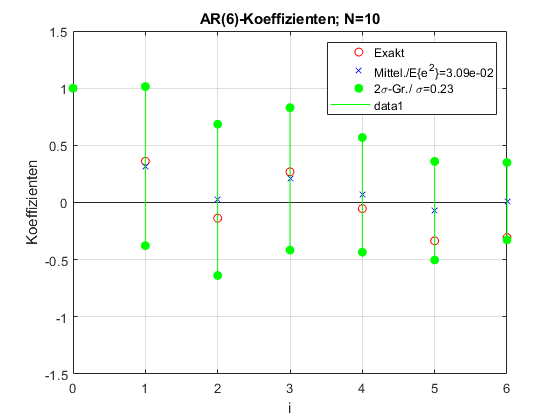

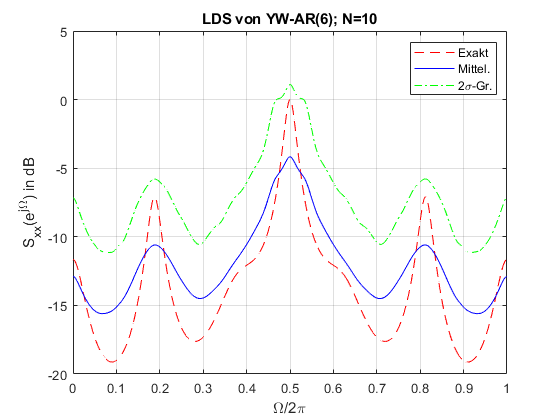

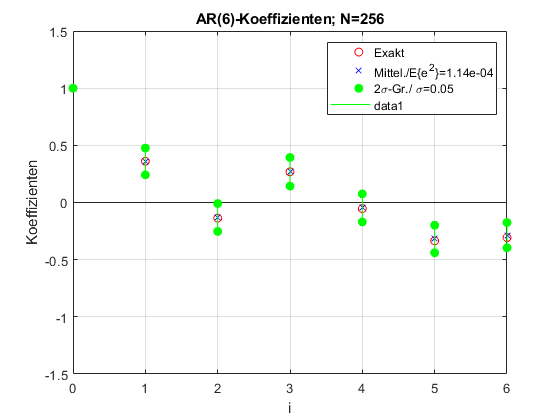

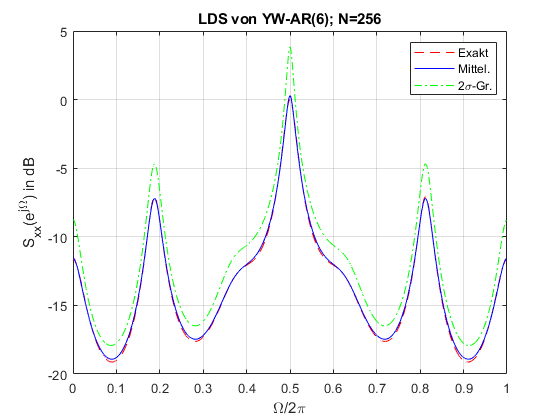

In [5]:
disp('....Bitte warten: Berechnung erfolgt.....');

N = [10 256];
N_vor = 80;
mc_run = 1e3;

for run0 = N
    Sxx_ar = zeros(mc_run,NFFT);
    Coeff = zeros(mc_run,n_a);
    
    for run1 = 1:mc_run
        noise = randn(1,run0+N_vor);
        x_all = filter(MA,AR,noise);
        x = x_all(N_vor+1:length(x_all));
        ARcoeff = lyw(x,n,1);
        Coeff(run1,:) = ARcoeff;
        Sxx_ar(run1,:) = abs(ones(1,NFFT)./fft(ARcoeff,NFFT)).^2;
    end
    
    Coeff_mean = mean(Coeff,1);
    Coeff_std = std(Coeff,1);
    C2sig_o = Coeff_mean+2*Coeff_std;
    C2sig_u = Coeff_mean-2*Coeff_std;
    Coeff_lst = mean(abs(AR-Coeff_mean).^2);
    Sxx_mean = mean(Sxx_ar,1);
    Sxx_2sigma = Sxx_mean+2*std(Sxx_ar,1);

    % # grafische Ausgabe # %
    figure;
    h1 = stem(0:n,AR,'ro');               hold on;
    h2 = stem(0:n,Coeff_mean,'bx');       hold on;
    h3 = stem(0:n,C2sig_o,'go','filled'); hold on;
    h4 = stem(0:n,C2sig_u,'go','filled');
    legend([h1(1),h2(1),h3(1)],'Exakt',['Mittel./E\{e^2\}=',sprintf('%1.2e',Coeff_lst)],...
        ['2\sigma-Gr./ \sigma=',sprintf('%1.2f',mean(Coeff_std))]);
    set(h1,'Linestyle','none');
    set(h2,'Linestyle','none');
    set(h3,'Linestyle','none');
    set(h4,'Linestyle','none');
    x_lines = [0:n; 0:n; nan*ones(1,n+1)];
    stddev_lines = [C2sig_u; C2sig_o; nan*ones(1,n+1)];
    plot(x_lines(:),stddev_lines(:),'g');
    title(sprintf('AR(%d)-Koeffizienten; N=%d',n,run0));
    xlabel('i');
    ylabel('Koeffizienten');
    grid;
    axis([0 n -1.5 1.5]);
    hold off;

    figure;
    h1 = plot(Omega_norm, 10*log10(Sxx_ex/max(Sxx_ex)),'r--');       hold on;
    h2 = plot(Omega_norm, 10*log10(Sxx_mean/max(Sxx_ex)),'b-');      hold on;
    h3 = plot(Omega_norm, 10*log10(Sxx_2sigma/max(Sxx_ex)),'g-.');   hold off;
    ylabel('S_{xx}(e^{j\Omega}) in dB');
    legend([h1,h2,h3],'Exakt','Mittel.','2\sigma-Gr.');
    title(sprintf('LDS von YW-AR(%d); N=%d',n, run0));
    xlabel('\Omega/2\pi');
    grid;
end